# E07 · Gratings, Bloch waves, and band gaps

Use momentum matching to find diffraction directions, then use a period’s transfer matrix to explain why a stack can reject a band of frequencies.

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Complex amplitudes and phase:** Track phase gained over one period and distinguish a phase factor from attenuation. Used here: Bloch factors describe how a field repeats through a structure. [Review: MIT OCW · Complex Arithmetic and Exponentials](https://ocw.mit.edu/courses/18-03sc-differential-equations-fall-2011/pages/unit-i-first-order-differential-equations/complex-arithmetic-and-exponentials/). Read the notes on Euler's formula, polar form, multiplication, and complex conjugation. The differential-equation applications can wait.
- **Matrices, eigenvectors, and modes:** Multiply 2 × 2 matrices and interpret their eigenvalues. Used here: A period's transfer matrix determines its propagating and decaying solutions. [Review: MIT OCW · Eigenvalues and Eigenvectors](https://ocw.mit.edu/courses/18-06sc-linear-algebra-fall-2011/pages/least-squares-determinants-and-eigenvalues/eigenvalues-and-eigenvectors/). Start with the lecture summary and one 2 × 2 worked problem. Focus on Av = λv and what changes when a matrix is applied repeatedly.

For the RCWA extension, review Fourier harmonics and basis truncation; the notebook introduces boundary matching and efficiencies.
- [TU Delft · Fourier analysis](https://qiweb.tudelft.nl/aoi/fourieranalysis/fourieranalysis/) — Use §4.1 for the transform pair, then §4.2.1–4.2.4 for linearity, scaling, shifts, and convolution. Consult §4.2.7 for two successive transforms.

**Python preparation:** Work with complex matrices and inspect convergence as the number of retained harmonics changes.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.

**Developed here:** Connect grating directions, Bloch propagation, and band gaps; calculate diffraction efficiencies in the extension.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Determine which grating orders propagate in each medium.
- Connect a finite Bragg mirror to an infinite crystal’s Bloch gap.
- Distinguish energy conservation from convergence in a truncated RCWA calculation.

**Model:** The browser grating panel is kinematic only. The separate Bragg stack is lossless, normally illuminated, with equal layer thicknesses and exterior index 1.9. The optional RCWA model is a 1D lamellar, isotropic, lossless TE layer; it rejects exact cutoffs. TM and nonperiodic structures require additional treatment.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e07_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.12.13 | NumPy 2.4.3 | SciPy 1.16.3 | Matplotlib 3.11.2


## 1 · Periodicity selects allowed directions

Translation by period Λ repeats the boundary, so a scattered tangential wavevector differs
from the incident one by m·2π/Λ. An order propagates only when its longitudinal wavevector
is real. This says where light may go, not how much power enters each order.
**Predict:** as Λ decreases at fixed wavelength, do more or fewer orders propagate?

Allowed orders and angles: [(np.int64(-1), np.float64(-34.147069974002896)), (np.int64(0), np.float64(12.000000000000002)), (np.int64(1), np.float64(77.72608519215471))]


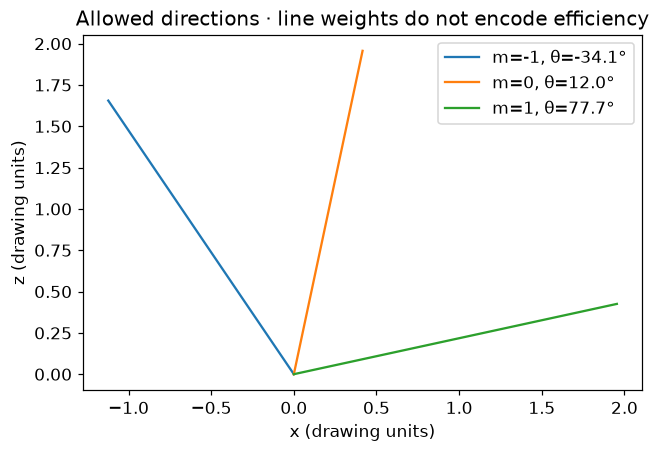

In [2]:
lam=1.;period=1.3;theta=np.deg2rad(12);orders=np.arange(-5,6)
sines=np.sin(theta)+orders*lam/period
allowed=abs(sines)<1
angles=np.rad2deg(np.arcsin(sines[allowed]))
print("Allowed orders and angles:",list(zip(orders[allowed],angles)))
assert np.max(abs(np.sin(np.deg2rad(angles))-np.sin(theta)-orders[allowed]*lam/period))<1e-14
fig,ax=plt.subplots(figsize=(7,4))
for order,angle in zip(orders[allowed],angles):
    ax.plot([0,2*np.sin(np.deg2rad(angle))],[0,2*np.cos(np.deg2rad(angle))],label=f"m={order}, θ={angle:.1f}°")
ax.set(xlabel="x (drawing units)",ylabel="z (drawing units)",title="Allowed directions · line weights do not encode efficiency")
ax.set_aspect("equal",adjustable="box")
ax.legend();show(fig,"01-grating-orders")

## 2 · A layered medium gives amplitudes as well as directions

A layer transfer matrix connects tangential fields at its two faces. Multiply matrices
in physical order and match the exterior waves. For a lossless stack R+T=1, including
the exterior-index flux factor. For an infinite period, cos(KΛ)=½ tr(M).
A real half-trace outside [-1,1] produces a complex Bloch wavevector and a band gap.

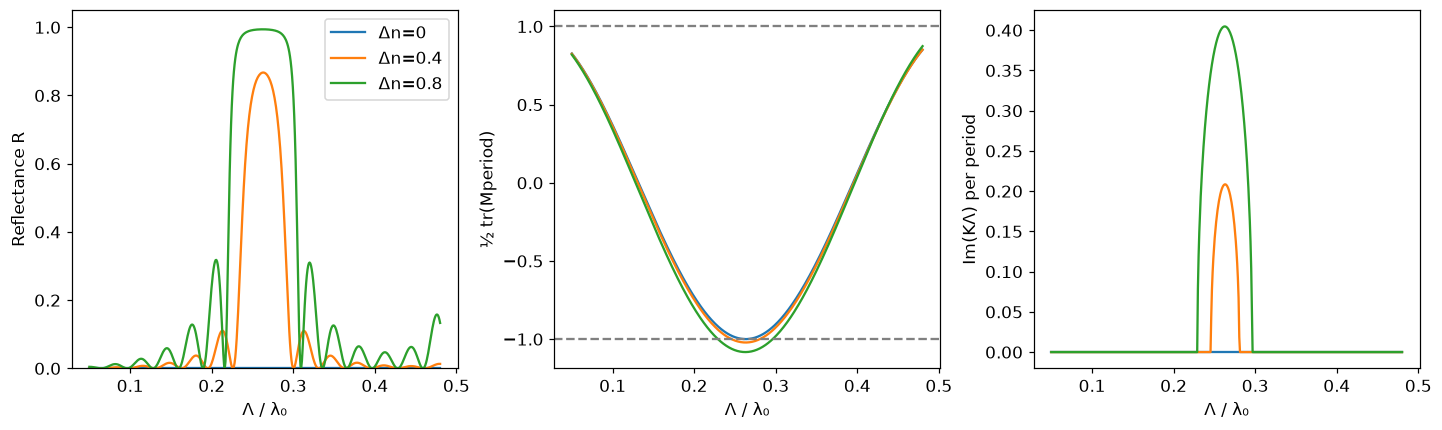

In [3]:
def layer_matrix(n, depth, lam):
    phase = 2*np.pi*n*depth/lam
    c, s = np.cos(phase), np.sin(phase)
    return np.array([[c, 1j*s/n], [1j*n*s, c]])


def stack_rt(lam, n1, n2, d1, d2, pairs, n_in, n_out):
    cell = layer_matrix(n2, d2, lam) @ layer_matrix(n1, d1, lam)
    A, B, C, D = np.linalg.matrix_power(cell, pairs).ravel()
    denom = n_out*A - C - n_in*n_out*B + n_in*D
    r = -(n_out*A-C+n_in*n_out*B-n_in*D)/denom
    t = 2*n_in/denom  # det(total matrix)=1; avoids cancellation at deep stop bands
    return abs(r)**2, (n_out/n_in)*abs(t)**2, 0.5*np.trace(cell).real



nu=np.linspace(.05,.48,501)
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
for contrast in [0,.4,.8]:
    n1,n2=1.9-contrast/2,1.9+contrast/2
    values=np.array([stack_rt(1/f,n1,n2,.5,.5,8,1.9,1.9) for f in nu])
    R,T,bloch_trace=values.T
    assert np.max(abs(R+T-1))<2e-12
    if contrast==0:assert np.max(R)<1e-25 and np.max(abs(bloch_trace))<=1+1e-14
    ax[0].plot(nu,R,label=f"Δn={contrast}")
    ax[1].plot(nu,bloch_trace)
    ax[2].plot(nu,np.arccosh(np.maximum(1,abs(bloch_trace))))
ax[0].set(xlabel="Λ / λ₀",ylabel="Reflectance R",ylim=(0,1.05));ax[0].legend()
ax[1].axhline(1,color="gray",ls="--");ax[1].axhline(-1,color="gray",ls="--")
ax[1].set(xlabel="Λ / λ₀",ylabel="½ tr(Mperiod)")
ax[2].set(xlabel="Λ / λ₀",ylabel="Im(KΛ) per period")
show(fig,"02-stack-and-bloch-gap")

## 3 · A finite stack is not an infinite crystal

An infinite gap concerns allowed Bloch eigenwaves. A finite stack has interfaces and a
finite thickness; reflection grows with period count but is not a perfect binary switch.
Transfer matrices can overflow for very thick evanescent stacks. These small lossless
examples are well-conditioned; large calculations should use scattering matrices.

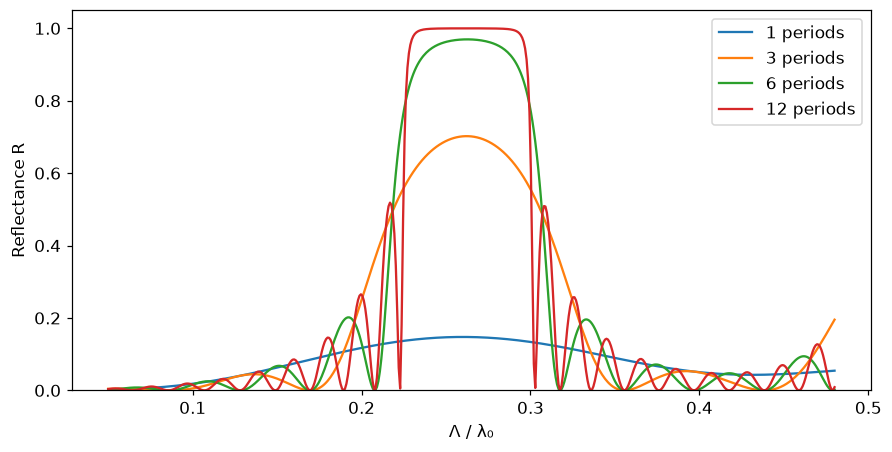

In [4]:
fig,ax=plt.subplots(figsize=(8,4))
for pairs in [1,3,6,12]:
    R=[stack_rt(1/f,1.5,2.3,.5,.5,pairs,1.9,1.9)[0] for f in nu]
    ax.plot(nu,R,label=f"{pairs} periods")
ax.set(xlabel="Λ / λ₀",ylabel="Reflectance R",ylim=(0,1.05));ax.legend()
show(fig,"03-finite-stack")

## Optional extension · A small TE rigorous coupled-wave calculation

Expand E_y and the binary grating permittivity in Fourier harmonics. Inside a layer,
diagonalize ε-convolution minus kx²; match E_y and its z derivative at both interfaces.
The solve below anchors forward amplitudes at the entrance and backward amplitudes
at the exit, so evanescent propagation only decays. It retains -M…M orders.

This implementation is for one lossless lamellar layer, nonmagnetic media, and TE
polarization. It is not a general TM or multilayer RCWA package. Avoid exact Rayleigh
cutoffs, and check order convergence separately from energy conservation: R+T=1
can hold even when individual efficiencies have not converged.

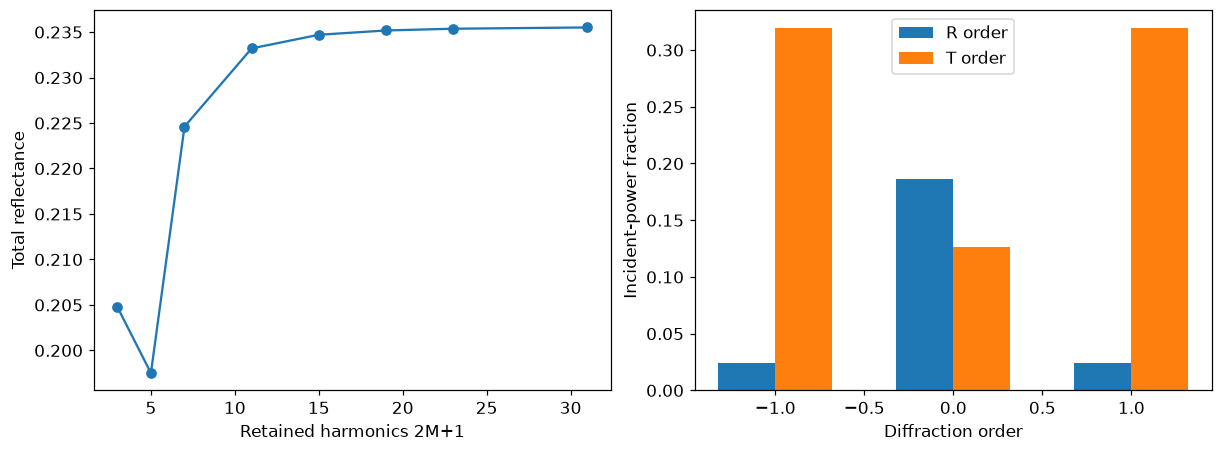

Largest flux error: 3.3306690738754696e-16 Final reflectance change: 0.00013871247772911932


In [5]:
def rcwa_te(lam=1.0, period=1.3, depth=0.45, fill=0.45,
            n_ridge=2.0, n_gap=1.0, n_in=1.0, n_out=1.0,
            theta=0.0, M=7):
    """E_y phasor uses exp(-i omega t), illumination travels +z; theta in radians.

    Positive real indices only; all lengths use the same unit. Retain orders
    -M...M. a is the forward modal amplitude at z=0; b is the backward amplitude
    at z=depth. Only decaying evanescent propagators occur in the boundary solve.
    """
    if not (lam > 0 and period > 0 and depth >= 0 and 0 <= fill <= 1):
        raise ValueError('Require positive wavelength/period, depth >= 0, fill in [0,1].')
    if not (isinstance(M, (int, np.integer)) and M >= 0 and abs(theta) < np.pi/2):
        raise ValueError('Require integer M >= 0 and |theta| < pi/2.')
    if min(n_ridge, n_gap, n_in, n_out) <= 0:
        raise ValueError('This reference supports positive real, lossless indices.')
    m = np.arange(-M, M+1)
    alpha = n_in*np.sin(theta) + m*lam/period  # k_x,m / k_0
    qi = np.sqrt((n_in*n_in-alpha*alpha).astype(complex))
    qt = np.sqrt((n_out*n_out-alpha*alpha).astype(complex))
    D = m[:, None] - m[None, :]
    C = n_gap**2*np.eye(len(m)) + (n_ridge**2-n_gap**2)*fill*np.sinc(D*fill)
    q2, W = np.linalg.eigh(C - np.diag(alpha*alpha))
    q = np.sqrt(q2.astype(complex))  # Re q >= 0; Im q >= 0
    if min(np.min(abs(q)), np.min(abs(qi)), np.min(abs(qt))) < 1e-8:
        raise ValueError('Exact/near cutoff: detune wavelength slightly and recheck convergence.')
    V = W*q[None, :]
    P = np.exp(1j*(2*np.pi/lam)*depth*q)
    QiW, QtW = qi[:, None]*W, qt[:, None]*W
    L = np.block([[QiW+V, (QiW-V)*P[None, :]],
                  [(QtW-V)*P[None, :], QtW+V]])
    incident = (m == 0).astype(complex)
    rhs = np.r_[2*qi*incident, np.zeros(len(m), complex)]
    ab = np.linalg.solve(L, rhs)
    a, b = np.split(ab, 2)
    r = W@(a+P*b) - incident
    t = W@(P*a+b)
    R, T = qi.real/qi[M].real*abs(r)**2, qt.real/qi[M].real*abs(t)**2
    residual = np.linalg.norm(L@ab-rhs)/(np.linalg.norm(L)*np.linalg.norm(ab)+np.linalg.norm(rhs))
    return dict(m=m, alpha=alpha, r=r, t=t, R=R, T=T,
                conservation=abs(1-R.sum()-T.sum()), residual=residual)


def airy(lam, n_in, n_film, n_out, depth, theta=0.0):
    """Independent homogeneous-film TE amplitudes at the film faces."""
    alpha = n_in*np.sin(theta)
    qi, qf, qt = np.sqrt(np.array([n_in*n_in, n_film*n_film, n_out*n_out])-alpha*alpha+0j)
    ri = (qi-qf)/(qi+qf)
    ro = (qf-qt)/(qf+qt)
    ph = np.exp(1j*2*np.pi/lam*qf*depth)
    denom = 1 + ri*ro*ph*ph
    return (ri+ro*ph*ph)/denom, 2*qi/(qi+qf)*2*qf/(qf+qt)*ph/denom



retained=[1,2,3,5,7,9,11,15]
reflectance=[];errors=[]
for M in retained:
    result=rcwa_te(M=M)
    reflectance.append(result['R'].sum());errors.append(result['conservation'])
    assert result['conservation']<1e-10 and result['residual']<1e-12
# Independent homogeneous-film Airy formula checks amplitudes, not just energy balance.
for fill in [0.,1.]:
    result=rcwa_te(fill=fill,n_gap=1.2,n_in=1.5,depth=.37,theta=.3,M=7)
    r,t=airy(1,1.5,1.2 if fill==0 else 2.,1,.37,.3)
    assert abs(result['r'][7]-r)<1e-12 and abs(result['t'][7]-t)<1e-12
assert abs(reflectance[-1]-reflectance[-2])<2e-3
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(2*np.array(retained)+1,reflectance,"o-")
ax[0].set(xlabel="Retained harmonics 2M+1",ylabel="Total reflectance")
last=rcwa_te(M=15);propagating=last['R']+last['T']>1e-10
ax[1].bar(last['m'][propagating]-.16,last['R'][propagating],.32,label="R order")
ax[1].bar(last['m'][propagating]+.16,last['T'][propagating],.32,label="T order")
ax[1].set(xlabel="Diffraction order",ylabel="Incident-power fraction");ax[1].legend()
show(fig,"04-rcwa-convergence")
print("Largest flux error:",max(errors),"Final reflectance change:",abs(reflectance[-1]-reflectance[-2]))

## A short lab report

**1. Count orders.** Predict the order count before changing wavelength, angle, or exit index.

**2. Build a mirror.** Compare two and ten periods at fixed index contrast, then remove the contrast.

**3. Convergence audit.** Report conservation, boundary residual, and changes in individual RCWA order powers.

### Worked reasoning

**Count orders.** Apply the propagation condition in the appropriate medium to every integer m; treat exact grazing separately.

**Build a mirror.** More periods strengthen finite-stack reflection in the same infinite-medium gap. No contrast removes the periodic scattering.

**Convergence audit.** A small residual or power-balance error alone does not bound truncation error. Retain more harmonics and compare complex t₀ as well.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [Moharam et al. · Stable rigorous coupled-wave analysis](https://opg.optica.org/josaa/abstract.cfm?uri=josaa-12-5-1068)
- [Li · Fourier factorization for discontinuous periodic structures](https://opg.optica.org/josaa/abstract.cfm?uri=josaa-13-9-1870)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e07_figures.zip


/tmp/optics-notebooks-xppq4daw/E07/e07_figures.zip